# RSNA Pneumonia — Stage 2 Verifier: RAD-DINO full fine-tuning, patient-grouped 5-fold CV
Two views (local + context crop) + proposal/geometry tabular stream. Layer-wise LR decay, head-only warm-up, drop-path, EMA,
modality dropout, IoU auxiliary loss, medical-safe GPU augmentation, flip TTA. Threshold picked on VAL only; metrics reported on pooled
out-of-fold TEST with patient-level bootstrap CIs.

In [1]:
!pip install -q transformers accelerate scikit-learn opencv-python-headless lightgbm

In [2]:
import os, gc, glob, math, hashlib, time, random, warnings
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt, lightgbm as lgb
from tqdm.auto import tqdm
from transformers import AutoModel, AutoImageProcessor
from torch.optim.swa_utils import AveragedModel
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
warnings.filterwarnings("ignore")

# ============================ CONFIG ============================
SEED = 42
WORK_DIR = "/kaggle/working"
OUT_DIR = os.path.join(WORK_DIR, "experiments", "raddino_cv"); os.makedirs(OUT_DIR, exist_ok=True)

# proposals / labels / crops
CONF_CUTOFF, IOU_TP, IOU_IGNORE_LO = 0.15, 0.40, 0.20   # IoU in [LO,TP) = ambiguous: excluded from BCE, kept for the IoU aux loss
LOCAL_PAD, CTX_SCALE, CTX_MIN_PX, IMG_SIZE = 0.15, 3.0, 192, 224
BOX_COORD_SIZE = None            # None -> boxes already in each image's pixel space
USE_DET_FEATURES = True

# model / optimisation
MODEL_NAME  = "microsoft/rad-dino"
BATCH_SIZE, EVAL_BS = 24, 64
EPOCHS, PATIENCE = 5, 3
BACKBONE_LR, LLRD, HEAD_LR = 1.5e-5, 0.75, 5e-4
WEIGHT_DECAY, WARMUP_FRAC, EMA_DECAY, GRAD_CLIP = 0.05, 0.1, 0.995, 1.0
FREEZE_EPOCHS = 0.4              # head-only warm-up (backbone under no_grad)
DROP_PATH     = 0.1              # stochastic depth
AUX_W         = 0.5              # IoU auxiliary loss weight
P_TAB_DROP, P_VIEW_DROP = 0.15, 0.10   # modality dropout (forces pixel path to carry signal)
USE_GC = False

# augmentation (geometry kept mild: the label is IoU-based)
AUG_ROT, AUG_SCALE, AUG_SHIFT, FLIP_P = 10.0, 0.10, 0.06, 0.5

# evaluation
TARGET_RECALL = 0.90
N_FOLDS, VAL_FRAC = 5, 0.15
RUN_FOLDS = list(range(N_FOLDS))  # e.g. [0] for a quick smoke test; finished folds are cached and skipped
N_BOOT = 300

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(SEED); torch.backends.cudnn.benchmark = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

Device: cuda Tesla T4


## 1. Stage 1 proposals ingestion

In [3]:
def discover_stage1_proposals():
    pats = [os.path.join(WORK_DIR, "test_candidate_proposals_epoch*.csv"), "/kaggle/input/**/test_candidate_proposals_epoch*.csv",
            os.path.join(WORK_DIR, "test_candidate_proposals.csv"), "/kaggle/input/**/test_candidate_proposals.csv",
            os.path.join(WORK_DIR, "experiments/**/test_candidate_proposals*.csv"), "/kaggle/input/**/experiments/**/test_candidate_proposals*.csv",
            "./test_candidate_proposals*.csv"]
    found = sorted({m for p in pats for m in glob.glob(p, recursive=True)}, reverse=True)
    if not found: raise FileNotFoundError("Stage 1 proposals CSV not found - attach the RT-DETR output dataset.")
    print("[STAGE 1]", found[0]); return found[0]

def pick(df, *names):
    for n in names:
        if n in df.columns: return n
    raise KeyError(f"None of {names} in {list(df.columns)}")

df = pd.read_csv(discover_stage1_proposals())
df["conf"] = df[pick(df, "confidence", "detector_confidence")].astype(float)
for k, (a, b) in dict(bx1=("pred_x1", "x1"), by1=("pred_y1", "y1"), bx2=("pred_x2", "x2"), by2=("pred_y2", "y2")).items():
    df[k] = df[pick(df, a, b)].astype(float)
iou_col = next((c for c in ["best_iou", "max_gt_iou"] if c in df.columns), None)
if iou_col is None: raise KeyError("Need a best_iou / max_gt_iou column to build labels.")
df["iou"] = df[iou_col].astype(float).fillna(0.0)
df["patientId"] = df["patientId"].astype(str)

n0 = len(df)
df = df[(df.conf >= CONF_CUTOFF) & (df.bx2 > df.bx1) & (df.by2 > df.by1)]
df = df.drop_duplicates(subset=["patientId", "bx1", "by1", "bx2", "by2"]).reset_index(drop=True)
df["is_tp"] = (df["iou"] >= IOU_TP).astype(int); df["is_fp"] = 1 - df["is_tp"]
print(f"proposals {len(df)}/{n0} | patients {df.patientId.nunique()} | TP rate {df.is_tp.mean():.3f} | proposals/patient {len(df)/df.patientId.nunique():.1f}")
print("box coord max (x2,y2):", df.bx2.max(), df.by2.max(), " <- must match image pixel space")

[STAGE 1] /kaggle/input/notebooks/prahlad214/rt-detr-pipeline/test_candidate_proposals_epoch20.csv
proposals 10094/10094 | patients 2018 | TP rate 0.121 | proposals/patient 5.0
box coord max (x2,y2): 635.95703 682.50336  <- must match image pixel space


## 2. Build two crops per proposal (local + wide context) straight from the radiographs
No silent black crops: missing images raise / are reported.

In [4]:
def build_image_index(pids):
    idx, need = {}, set(pids)
    for root in ["/kaggle/input", WORK_DIR]:
        for r, _, fs in os.walk(root):
            for f in fs:
                stem, ext = os.path.splitext(f)
                if stem in need and stem not in idx and ext.lower() in (".jpg", ".jpeg", ".png"): idx[stem] = os.path.join(r, f)
            if len(idx) == len(need): return idx
    return idx

def safe_crop(img, x1, y1, x2, y2):
    H, W = img.shape
    x1, y1, x2, y2 = int(round(x1)), int(round(y1)), int(round(x2)), int(round(y2))
    if x2 <= x1 or y2 <= y1: return None
    sub = img[max(0, y1):min(H, y2), max(0, x1):min(W, x2)]
    if sub.size == 0: return None
    return cv2.copyMakeBorder(sub, max(0, -y1), max(0, y2 - H), max(0, -x1), max(0, x2 - W), cv2.BORDER_CONSTANT, value=0)

def make_views(img, x1, y1, x2, y2):
    w, h = x2 - x1, y2 - y1
    loc = safe_crop(img, x1 - w * LOCAL_PAD, y1 - h * LOCAL_PAD, x2 + w * LOCAL_PAD, y2 + h * LOCAL_PAD)
    side = max(max(w, h) * CTX_SCALE, CTX_MIN_PX); cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    ctx = safe_crop(img, cx - side / 2, cy - side / 2, cx + side / 2, cy + side / 2)
    if loc is None or ctx is None: return None
    r = lambda a: cv2.resize(a, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA if a.shape[0] > IMG_SIZE else cv2.INTER_LINEAR)
    return np.stack([r(loc), r(ctx)])

key = hashlib.md5(df[["bx1", "by1", "bx2", "by2"]].values.tobytes() + str((LOCAL_PAD, CTX_SCALE, CTX_MIN_PX, IMG_SIZE, BOX_COORD_SIZE)).encode()).hexdigest()[:10]
cache = os.path.join(OUT_DIR, f"crops_{key}.npz")
if os.path.exists(cache):
    z = np.load(cache); CROPS_NP, IMG_WH, valid = z["crops"], z["wh"], z["valid"]; print("[CACHE HIT]", cache)
else:
    index = build_image_index(set(df.patientId)); print("images found:", len(index), "/", df.patientId.nunique())
    CROPS_NP = np.zeros((len(df), 2, IMG_SIZE, IMG_SIZE), np.uint8); IMG_WH = np.zeros((len(df), 2), np.float32); valid = np.zeros(len(df), bool)
    def crop_patient(item):
        pid, g = item; p = index.get(pid)
        if p is None: return []
        img = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
        if img is None: return []
        H, W = img.shape; sx, sy = (W / BOX_COORD_SIZE, H / BOX_COORD_SIZE) if BOX_COORD_SIZE else (1.0, 1.0)
        out = []
        for i, x1, y1, x2, y2 in zip(g.index, g.bx1, g.by1, g.bx2, g.by2):
            v = make_views(img, x1 * sx, y1 * sy, x2 * sx, y2 * sy)
            if v is not None: out.append((i, v, W / sx, H / sy))
        return out
    with ThreadPoolExecutor(8) as ex:
        for res in tqdm(ex.map(crop_patient, list(df.groupby("patientId"))), total=df.patientId.nunique(), desc="crops"):
            for i, v, w_, h_ in res: CROPS_NP[i] = v; IMG_WH[i] = (w_, h_); valid[i] = True
    np.savez(cache, crops=CROPS_NP, wh=IMG_WH, valid=valid)

miss = (~valid).sum(); print(f"valid crops {valid.sum()}/{len(valid)} (missing {miss})")
if miss / len(valid) > 0.01: raise RuntimeError("More than 1% of crops missing - fix image paths / box scale before training.")
df = df[valid].reset_index(drop=True); CROPS_NP = CROPS_NP[valid]; IMG_WH = IMG_WH[valid]
assert (CROPS_NP.reshape(len(df), -1).max(1) > 0).all(), "black crops present"
oob = ((df.bx2.values > IMG_WH[:, 0] * 1.01) | (df.by2.values > IMG_WH[:, 1] * 1.01)).mean()
if oob > 0.01: raise RuntimeError(f"{oob:.1%} of boxes fall outside the image -> wrong box coordinate space (set BOX_COORD_SIZE).")

images found: 2018 / 2018


crops:   0%|          | 0/2018 [00:00<?, ?it/s]

valid crops 10094/10094 (missing 0)


## 3. Tabular stream: 10-D normalized geometry + proposal-context stats (rank, overlap, per-image max conf)

In [5]:
def iou_matrix(b):
    x1 = np.maximum(b[:, None, 0], b[None, :, 0]); y1 = np.maximum(b[:, None, 1], b[None, :, 1])
    x2 = np.minimum(b[:, None, 2], b[None, :, 2]); y2 = np.minimum(b[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None); a = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (a[:, None] + a[None, :] - inter + 1e-9)

W_, H_ = IMG_WH[:, 0], IMG_WH[:, 1]
nx1, ny1 = np.clip(df.bx1.values / W_, 0, 1), np.clip(df.by1.values / H_, 0, 1)
nx2, ny2 = np.clip(df.bx2.values / W_, 0, 1), np.clip(df.by2.values / H_, 0, 1)
w, h = np.clip(nx2 - nx1, 1e-4, 1), np.clip(ny2 - ny1, 1e-4, 1); cx, cy = (nx1 + nx2) / 2, (ny1 + ny2) / 2
asp, side = np.log((w * W_) / (h * H_)), np.log(np.maximum(w * W_, h * H_))
spatial = np.stack([nx1, ny1, nx2, ny2, cx, cy, w, h, w * h, np.abs(cx - 0.5), asp, side], 1).astype(np.float32)   # 12-D

ctxf = np.zeros((len(df), 8), np.float32)
for pid, g in df.groupby("patientId"):
    ii = g.index.values; conf = g.conf.values; b = g[["bx1", "by1", "bx2", "by2"]].values; n = len(ii)
    rank = np.empty(n); rank[np.argsort(-conf)] = np.arange(n)
    iou = iou_matrix(b); np.fill_diagonal(iou, 0); higher = conf[None, :] > conf[:, None]
    cons = ((iou > 0.3) * conf[None, :]).sum(1)                       # detector agreement around this box
    ctxf[ii] = np.stack([rank, np.full(n, n), np.full(n, conf.max()), conf / conf.max(), (iou * higher).max(1), (iou > 0.3).sum(1), cons, rank / max(n - 1, 1)], 1)
c = np.clip(df.conf.values, 1e-4, 1 - 1e-4)
det = np.column_stack([c, np.log(c / (1 - c)), np.log1p(ctxf[:, 0]), np.log1p(ctxf[:, 1]), ctxf[:, 2], ctxf[:, 3], ctxf[:, 4], ctxf[:, 5], np.log1p(ctxf[:, 6]), ctxf[:, 7]]).astype(np.float32)
TAB_RAW = np.hstack([spatial, det]) if USE_DET_FEATURES else spatial        # RAW (scaled per fold, no leakage)
print("tabular dim:", TAB_RAW.shape[1])

tabular dim: 22


## 4. Patient-level split: 60 / 20 / 20 (train / val / test). Val = early stopping + threshold. Test = reported once.

In [6]:
LABELS = df.is_tp.values.astype(np.float32)
ambig = (df.iou.values >= IOU_IGNORE_LO) & (df.iou.values < IOU_TP); KEEP = ~ambig
PID = pd.factorize(df.patientId)[0]
ps = df.groupby("patientId")["is_tp"].max().reset_index()

FOLDS = []
for k, (a, b) in enumerate(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(ps.patientId, ps.is_tp)):
    tr_p, va_p = train_test_split(ps.patientId.values[a], test_size=VAL_FRAC, stratify=ps.is_tp.values[a], random_state=SEED)
    te_p = set(ps.patientId.values[b]); tr_p, va_p = set(tr_p), set(va_p)
    assert not (tr_p & va_p) and not (tr_p & te_p) and not (va_p & te_p)
    FOLDS.append({n: np.where(df.patientId.isin(s))[0] for n, s in zip(("tr", "va", "te"), (tr_p, va_p, te_p))})
    f = FOLDS[-1]; print(f"fold {k}: train {len(f['tr'])} (TP {int(LABELS[f['tr']].sum())}) | val {len(f['va'])} (TP {int(LABELS[f['va']].sum())}) | test {len(f['te'])} (TP {int(LABELS[f['te']].sum())})")
print(f"base rate {LABELS.mean():.4f} | detector-conf AUROC (all) {roc_auc_score(LABELS, df.conf.values):.4f} AUPRC {average_precision_score(LABELS, df.conf.values):.4f}")

fold 0: train 6898 (TP 839) | val 1195 (TP 141) | test 2001 (TP 241)
fold 1: train 6871 (TP 836) | val 1208 (TP 140) | test 2015 (TP 245)
fold 2: train 6892 (TP 830) | val 1183 (TP 148) | test 2019 (TP 243)
fold 3: train 6951 (TP 825) | val 1119 (TP 146) | test 2024 (TP 250)
fold 4: train 6810 (TP 827) | val 1249 (TP 152) | test 2035 (TP 242)
base rate 0.1210 | detector-conf AUROC (all) 0.7998 AUPRC 0.4305


## 5. Model: fully trainable RAD-DINO (shared across both views) + tabular MLP + fusion head

In [7]:
proc = AutoImageProcessor.from_pretrained(MODEL_NAME)
MEAN = torch.tensor(proc.image_mean, device=DEVICE).view(1, 1, 3, 1, 1)
STD  = torch.tensor(proc.image_std,  device=DEVICE).view(1, 1, 3, 1, 1)
CROPS = torch.from_numpy(CROPS_NP).to(DEVICE); del CROPS_NP; gc.collect()          # ~1 GB uint8 on GPU -> no CPU indexing in the loop
TAB_RAW_T = torch.from_numpy(TAB_RAW).to(DEVICE)
Y_T   = torch.from_numpy(LABELS).to(DEVICE)
IOU_T = torch.from_numpy(np.clip(df.iou.values, 0, 1).astype(np.float32)).to(DEVICE)
KEEP_T = torch.from_numpy(KEEP).to(DEVICE)
NORM = {"mu": None, "sd": None}                                                     # set per fold from train-only statistics
sig = lambda z: 1 / (1 + np.exp(-z))

def flip_raw(t):                    # horizontal flip: mirror nx1, nx2, cx (cols 0, 2, 4); everything else is flip-invariant
    r = t.clone(); r[:, 0], r[:, 2], r[:, 4] = 1 - t[:, 2], 1 - t[:, 0], 1 - t[:, 4]; return r

class Verifier(nn.Module):
    def __init__(self, tab_dim, d=256, p=0.3):
        super().__init__()
        self.backbone = AutoModel.from_pretrained(MODEL_NAME, drop_path_rate=DROP_PATH)
        if USE_GC: self.backbone.gradient_checkpointing_enable()
        hid = self.backbone.config.hidden_size; self.bb_frozen = False
        mk = lambda: nn.Sequential(nn.LayerNorm(2 * hid), nn.Dropout(p), nn.Linear(2 * hid, d), nn.GELU())
        self.p_local, self.p_ctx = mk(), mk()
        self.tab = nn.Sequential(nn.Linear(tab_dim, 64), nn.LayerNorm(64), nn.GELU(), nn.Dropout(0.1), nn.Linear(64, 64), nn.GELU())
        self.head = nn.Sequential(nn.Dropout(p), nn.Linear(4 * d + 64, d), nn.GELU(), nn.Dropout(p), nn.Linear(d, 2))   # [tp_logit, iou_logit]
    def forward(self, x, t):
        B = x.shape[0]
        with torch.set_grad_enabled(torch.is_grad_enabled() and not self.bb_frozen):
            h = self.backbone(pixel_values=x.flatten(0, 1)).last_hidden_state
        f = torch.cat([h[:, 0], h[:, 1:].mean(1)], 1).view(B, 2, -1)
        zl, zc, zt = self.p_local(f[:, 0]), self.p_ctx(f[:, 1]), self.tab(t)
        if self.training:
            zc = zc * (torch.rand(B, 1, device=x.device) > P_VIEW_DROP).to(zc.dtype)
            zt = zt * (torch.rand(B, 1, device=x.device) > P_TAB_DROP).to(zt.dtype)
        return self.head(torch.cat([zl, zc, zl * zc, zl - zc, zt], 1))

# ---------- augmentation (GPU, per-sample) ----------
def _blur(x, sigma, k=5):
    r = torch.arange(k, device=x.device, dtype=x.dtype) - k // 2; g = torch.exp(-(r ** 2) / (2 * sigma ** 2)); g = g / g.sum()
    x = F.conv2d(F.pad(x, (k // 2,) * 4, mode="reflect"), g.view(1, 1, 1, k)); return F.conv2d(x, g.view(1, 1, k, 1))

def _erase(x, p, amin, amax):       # x: (n,1,H,W) random rectangle -> image mean
    n, _, H, W = x.shape; dev = x.device
    area = (torch.rand(n, device=dev) * (amax - amin) + amin) * H * W; ar = torch.exp((torch.rand(n, device=dev) * 2 - 1) * math.log(3))
    eh, ew = (area * ar).sqrt().clamp(4, H - 1), (area / ar).sqrt().clamp(4, W - 1)
    y0, x0 = torch.rand(n, device=dev) * (H - eh), torch.rand(n, device=dev) * (W - ew)
    yy, xx = torch.arange(H, device=dev).view(1, H, 1), torch.arange(W, device=dev).view(1, 1, W)
    m = (yy >= y0.view(n, 1, 1)) & (yy < (y0 + eh).view(n, 1, 1)) & (xx >= x0.view(n, 1, 1)) & (xx < (x0 + ew).view(n, 1, 1))
    m = (m & (torch.rand(n, device=dev) < p).view(n, 1, 1)).unsqueeze(1)
    return torch.where(m, x.mean((1, 2, 3), keepdim=True).expand_as(x), x)

def gpu_augment(x):                 # x: (B,2,1,H,W) in [0,1] -> (x_aug, flip_mask (B,))
    B, V, _, H, W = x.shape; n = B * V; dev = x.device
    x = x.reshape(n, 1, H, W); u = lambda: torch.rand(n, device=dev) * 2 - 1
    ang, sc = u() * math.radians(AUG_ROT), 1 + u() * AUG_SCALE; cos, sin = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([cos, -sin, u() * AUG_SHIFT], 1), torch.stack([sin, cos, u() * AUG_SHIFT], 1)], 1)
    x = F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), padding_mode="border", align_corners=False)
    fm = torch.rand(B, device=dev) < FLIP_P                                              # one flip decision per proposal (both views)
    x5 = x.view(B, V, 1, H, W); x = torch.where(fm.view(B, 1, 1, 1, 1), x5.flip(-1), x5).reshape(n, 1, H, W)
    x = x.clamp(1e-4, 1) ** torch.exp(u() * 0.25).view(n, 1, 1, 1)                      # gamma (exposure)
    m = x.mean((1, 2, 3), keepdim=True)
    x = (x - m) * (1 + u().view(n, 1, 1, 1) * 0.20) + m + u().view(n, 1, 1, 1) * 0.08  # contrast / brightness
    x = torch.where((torch.rand(n, device=dev) < 0.2).view(n, 1, 1, 1), _blur(x, random.uniform(0.7, 1.3)), x)
    x = x + torch.randn_like(x) * ((torch.rand(n, 1, 1, 1, device=dev) < 0.5).float() * torch.rand(n, 1, 1, 1, device=dev) * 0.03)
    x = x.clamp(0, 1).view(B, V, 1, H, W)
    return torch.stack([_erase(x[:, 0], 0.15, 0.02, 0.06), _erase(x[:, 1], 0.40, 0.03, 0.12)], 1), fm

def load(idx):
    it = torch.from_numpy(idx).to(DEVICE)
    return CROPS[it].float().div_(255).unsqueeze(2), TAB_RAW_T[it], it
def prep(x, t):
    return (x.expand(-1, -1, 3, -1, -1) - MEAN) / STD, ((t - NORM["mu"]) / NORM["sd"]).clamp(-6, 6)
def train_batch(idx):
    x, t, it = load(idx); x, fm = gpu_augment(x); t = torch.where(fm.view(-1, 1), flip_raw(t), t); x, t = prep(x, t)
    return x, t, Y_T[it].unsqueeze(1), IOU_T[it].unsqueeze(1), KEEP_T[it].float().unsqueeze(1)

@torch.no_grad()
def predict(m, idx, tta=False):     # -> logits (N,2): [tp, iou]
    m.eval(); out = []
    for i in range(0, len(idx), EVAL_BS):
        x, t, _ = load(idx[i:i + EVAL_BS])
        with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            lg = m(*prep(x, t)).float()
            if tta: lg = (lg + m(*prep(x.flip(-1), flip_raw(t))).float()) / 2
        out.append(lg.cpu().numpy())
    return np.concatenate(out)

def param_groups(model):
    L = model.backbone.config.num_hidden_layers; groups = {}
    for n, p in model.named_parameters():
        bb = n.startswith("backbone.")
        if bb:
            if ".encoder.layer." in n: lid = int(n.split(".encoder.layer.")[1].split(".")[0]) + 1
            elif "layernorm" in n and "encoder" not in n: lid = L + 1
            else: lid = 0
            lr = BACKBONE_LR * (LLRD ** (L + 1 - lid))
        else: lr = HEAD_LR
        nd = p.ndim <= 1 or n.endswith(".bias") or any(s in n for s in ("position_embeddings", "cls_token", "mask_token"))
        groups.setdefault((lr, nd, bb), []).append(p)
    return [dict(params=ps, lr=lr, weight_decay=0.0 if nd else WEIGHT_DECAY, bb=bb) for (lr, nd, bb), ps in groups.items()]

preprocessor_config.json:   0%|          | 0.00/756 [00:00<?, ?B/s]

## 6. Train (everything unfrozen)

In [8]:
def cos_sched(start, warm, total):
    def f(s):
        if s < start: return 0.0
        s -= start
        return (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - start - warm)))
    return f

def fit(tr, va, seed, tag):
    seed_all(seed); model = Verifier(TAB_RAW.shape[1]).to(DEVICE)
    clean = tr[KEEP[tr]]; n_pos = LABELS[clean].sum(); n_neg = len(clean) - n_pos
    bce = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([math.sqrt(n_neg / n_pos)], device=DEVICE), reduction="none")
    groups = param_groups(model); opt = torch.optim.AdamW(groups, betas=(0.9, 0.999))
    spe = math.ceil(len(tr) / BATCH_SIZE); total = EPOCHS * spe; frz = int(FREEZE_EPOCHS * spe); warm = int(WARMUP_FRAC * total)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, [cos_sched(frz if g["bb"] else 0, warm, total) for g in groups])
    amp = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")
    d = {"v": 0.0}; ema = AveragedModel(model, avg_fn=lambda a, c, n: a * d["v"] + c * (1 - d["v"]), use_buffers=True)   # warm-up decay
    print(f"[{tag}] trainable {sum(p.numel() for p in model.parameters() if p.requires_grad)/1e6:.1f}M | steps/ep {spe} | head-only steps {frz}")
    best, best_state, bad, hist, step = -1, None, 0, [], 0; rng = np.random.default_rng(seed); yv = LABELS[va]
    for ep in range(1, EPOCHS + 1):
        model.train(); perm = rng.permutation(tr); run = 0.0; t0 = time.time()
        for i in range(0, len(perm), BATCH_SIZE):
            b = perm[i:i + BATCH_SIZE]
            if len(b) < 4: continue
            model.bb_frozen = step < frz
            x, t, y, iou, keep = train_batch(b)
            with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE.type == "cuda"):
                out = model(x, t).float()
            l_tp = (bce(out[:, :1], y) * keep).sum() / keep.sum().clamp(min=1)            # ambiguous boxes excluded from BCE
            loss = l_tp + AUX_W * F.binary_cross_entropy_with_logits(out[:, 1:], iou)     # soft IoU target on ALL boxes
            opt.zero_grad(set_to_none=True); amp.scale(loss).backward(); amp.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP); amp.step(opt); amp.update(); sched.step()
            step += 1; d["v"] = min(EMA_DECAY, (1 + step) / (10 + step)); ema.update_parameters(model); run += l_tp.item() * len(b)
        lv = predict(ema.module, va); pv_ = sig(lv[:, 0])
        auc, ap = roc_auc_score(yv, pv_), average_precision_score(yv, pv_); hist.append((ep, run / len(perm), auc, ap))
        print(f"[{tag}] ep {ep:02d} | loss {run/len(perm):.4f} | val AUROC {auc:.4f} AUPRC {ap:.4f} | {time.time()-t0:.0f}s")
        if ap > best + 1e-3: best, bad = ap, 0; best_state = {k: v.detach().cpu().clone() for k, v in ema.module.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE: print("early stop"); break
    ema.module.load_state_dict(best_state); torch.save(best_state, os.path.join(OUT_DIR, f"{tag}.pt"))
    del model, opt; gc.collect(); torch.cuda.empty_cache()
    return ema.module.eval(), np.array(hist)

RES = {}
for k in RUN_FOLDS:
    path = os.path.join(OUT_DIR, f"fold{k}_preds.npz")
    if os.path.exists(path): RES[k] = dict(np.load(path)); print(f"[fold {k}] cached"); continue
    f = FOLDS[k]; tr, va, te = f["tr"], f["va"], f["te"]; clean = tr[KEEP[tr]]
    sc = StandardScaler().fit(TAB_RAW[clean])                                           # train-only statistics
    NORM["mu"], NORM["sd"] = torch.tensor(sc.mean_, dtype=torch.float32, device=DEVICE), torch.tensor(sc.scale_, dtype=torch.float32, device=DEVICE)
    TABN = np.clip(sc.transform(TAB_RAW), -6, 6)
    gbm = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.03, max_depth=4, num_leaves=15, subsample=0.8, subsample_freq=1,
                             colsample_bytree=0.8, class_weight="balanced", random_state=SEED, verbose=-1).fit(TABN[clean], LABELS[clean])
    model, hist = fit(tr, va, SEED + k, f"raddino_fold{k}")
    RES[k] = dict(va=va, te=te, lv=predict(model, va, tta=FLIP_P > 0), lt=predict(model, te, tta=FLIP_P > 0),
                  gv=gbm.predict_proba(TABN[va])[:, 1], gt=gbm.predict_proba(TABN[te])[:, 1], hist=hist)
    np.savez(path, **RES[k]); del model; gc.collect(); torch.cuda.empty_cache()

config.json:   0%|          | 0.00/879 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

[raddino_fold0] trainable 87.7M | steps/ep 288 | head-only steps 115
[raddino_fold0] ep 01 | loss 0.6179 | val AUROC 0.8530 AUPRC 0.5015 | 136s
[raddino_fold0] ep 02 | loss 0.4997 | val AUROC 0.8662 AUPRC 0.5469 | 183s
[raddino_fold0] ep 03 | loss 0.4692 | val AUROC 0.8660 AUPRC 0.5499 | 184s
[raddino_fold0] ep 04 | loss 0.4396 | val AUROC 0.8674 AUPRC 0.5544 | 184s
[raddino_fold0] ep 05 | loss 0.4307 | val AUROC 0.8649 AUPRC 0.5446 | 184s


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

[raddino_fold3] trainable 87.7M | steps/ep 290 | head-only steps 116
[raddino_fold3] ep 01 | loss 0.6325 | val AUROC 0.8665 AUPRC 0.5798 | 139s
[raddino_fold3] ep 02 | loss 0.4888 | val AUROC 0.8749 AUPRC 0.5901 | 185s
[raddino_fold3] ep 03 | loss 0.4687 | val AUROC 0.8719 AUPRC 0.5853 | 185s
[raddino_fold3] ep 04 | loss 0.4363 | val AUROC 0.8725 AUPRC 0.5851 | 185s
[raddino_fold3] ep 05 | loss 0.4220 | val AUROC 0.8714 AUPRC 0.5837 | 185s
early stop


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

[raddino_fold4] trainable 87.7M | steps/ep 284 | head-only steps 113
[raddino_fold4] ep 01 | loss 0.6131 | val AUROC 0.8926 AUPRC 0.6158 | 138s
[raddino_fold4] ep 02 | loss 0.4983 | val AUROC 0.9080 AUPRC 0.6459 | 182s
[raddino_fold4] ep 03 | loss 0.4580 | val AUROC 0.9103 AUPRC 0.6474 | 182s
[raddino_fold4] ep 04 | loss 0.4374 | val AUROC 0.9072 AUPRC 0.6514 | 182s
[raddino_fold4] ep 05 | loss 0.4160 | val AUROC 0.9068 AUPRC 0.6529 | 182s


## 7. Held-out TEST results + clinical FP-pruning (threshold & alpha chosen on VAL only)

In [9]:
pool = lambda n: np.concatenate([RES[k][n] for k in RUN_FOLDS])
va_i, te_i, LV, LT, GV, GT = pool("va"), pool("te"), pool("lv"), pool("lt"), pool("gv"), pool("gt")
yv, yt = LABELS[va_i], LABELS[te_i]
lgt = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
zs = lambda a, ref: (a - ref.mean()) / (ref.std() + 1e-9)

# 1) verifier score head chosen on VAL (classifier / IoU / mix)
heads = {"tp": (LV[:, 0], LT[:, 0]), "iou": (LV[:, 1], LT[:, 1]), "mix": (LV.mean(1), LT.mean(1))}
ap_v = {k: average_precision_score(yv, v[0]) for k, v in heads.items()}; hk = max(ap_v, key=ap_v.get)
print("score head (VAL AUPRC):", {k: round(v, 4) for k, v in ap_v.items()}, "->", hk)
vv, vt = heads[hk]; gvl, gtl = lgt(GV), lgt(GT)

# 2) blend with LightGBM in z-scored logit space, weight chosen on VAL
ws = np.linspace(0, 1, 11); apw = [average_precision_score(yv, w * zs(vv, vv) + (1 - w) * zs(gvl, gvl)) for w in ws]; w_b = ws[int(np.argmax(apw))]
print(f"blend weight (verifier) = {w_b:.1f}")
METHODS = {"Detector conf":        (df.conf.values[va_i], df.conf.values[te_i]),
           "LightGBM tabular":     (gvl, gtl),
           "RAD-DINO verifier":    (vv, vt),
           "Verifier+LGBM blend":  (w_b * zs(vv, vv) + (1 - w_b) * zs(gvl, gvl), w_b * zs(vt, vv) + (1 - w_b) * zs(gtl, gvl))}

# 3) patient-level bootstrap
codes = PID[te_i]; order = np.argsort(codes, kind="stable"); _, st = np.unique(codes[order], return_index=True)
groups = np.split(order, st[1:]); NPAT = len(groups); rng = np.random.default_rng(SEED)
BOOT = [np.concatenate([groups[j] for j in rng.integers(0, NPAT, NPAT)]) for _ in range(N_BOOT)]
ci = lambda vals: (np.percentile(vals, 2.5), np.percentile(vals, 97.5))
print("\n" + "=" * 92 + f"\nPOOLED OUT-OF-FOLD TEST  (folds {RUN_FOLDS}, {len(te_i)} proposals, {int(yt.sum())} TPs, {NPAT} patients)\n" + "=" * 92)
for name, (_, st_) in METHODS.items():
    a, p = roc_auc_score(yt, st_), average_precision_score(yt, st_)
    ca = ci([roc_auc_score(yt[b], st_[b]) for b in BOOT]); cp = ci([average_precision_score(yt[b], st_[b]) for b in BOOT])
    print(f"{name:<22} AUROC {a:.4f} [{ca[0]:.3f}-{ca[1]:.3f}] | AUPRC {p:.4f} [{cp[0]:.3f}-{cp[1]:.3f}]")
for a_, b_ in [("RAD-DINO verifier", "LightGBM tabular"), ("Verifier+LGBM blend", "LightGBM tabular")]:
    d_ = [average_precision_score(yt[b], METHODS[a_][1][b]) - average_precision_score(yt[b], METHODS[b_][1][b]) for b in BOOT]
    print(f"paired dAUPRC {a_} - {b_}: {np.mean(d_):+.4f} [{ci(d_)[0]:+.4f}, {ci(d_)[1]:+.4f}]  ({'significant' if ci(d_)[0] > 0 else 'NOT significant'})")

# 4) clinical FP pruning: tau = highest val threshold that still keeps TARGET_RECALL of val TPs
def pick_tau(sv): pos = np.sort(sv[yv == 1]); return pos[int(np.floor((1 - TARGET_RECALL) * len(pos)))]
def pm(s, tau, b):
    keep = s[b] >= tau; y = yt[b]; tp, fp = (y * keep).sum(), ((1 - y) * keep).sum()
    return dict(recall=tp / max(y.sum(), 1), precision=tp / max(tp + fp, 1), fp_img=fp / NPAT, dfp=100 * (1 - fp / max((1 - y).sum(), 1)))
rows = []; full = np.arange(len(te_i))
for name, (sv_, st_) in METHODS.items():
    tau = pick_tau(sv_); m0 = pm(st_, tau, full); bs = [pm(st_, tau, b) for b in BOOT]; r = dict(method=name, tau=round(float(tau), 3))
    for kx in ("recall", "precision", "fp_img", "dfp"):
        lo, hi = ci([x[kx] for x in bs]); r[kx] = f"{m0[kx]:.3f} [{lo:.3f}-{hi:.3f}]"
    rows.append(r)
res = pd.DataFrame(rows); base_fp_img = ((1 - yt).sum()) / NPAT
print(f"\nPRUNING @ val-selected tau (keep >= {TARGET_RECALL:.0%} of val TPs) | baseline FP/img = {base_fp_img:.2f}\n" + res.to_string(index=False))

score head (VAL AUPRC): {'tp': np.float64(0.578), 'iou': np.float64(0.5615), 'mix': np.float64(0.5738)} -> tp
blend weight (verifier) = 0.6

POOLED OUT-OF-FOLD TEST  (folds [0, 1, 2, 3, 4], 10094 proposals, 1221 TPs, 2018 patients)
Detector conf          AUROC 0.7998 [0.787-0.813] | AUPRC 0.4305 [0.402-0.459]
LightGBM tabular       AUROC 0.8864 [0.876-0.897] | AUPRC 0.5560 [0.519-0.589]
RAD-DINO verifier      AUROC 0.8861 [0.876-0.896] | AUPRC 0.5537 [0.520-0.587]
Verifier+LGBM blend    AUROC 0.8913 [0.881-0.901] | AUPRC 0.5667 [0.532-0.598]
paired dAUPRC RAD-DINO verifier - LightGBM tabular: -0.0024 [-0.0238, +0.0178]  (NOT significant)
paired dAUPRC Verifier+LGBM blend - LightGBM tabular: +0.0108 [-0.0049, +0.0255]  (NOT significant)

PRUNING @ val-selected tau (keep >= 90% of val TPs) | baseline FP/img = 4.40
             method    tau              recall           precision              fp_img                    dfp
      Detector conf  0.200 0.907 [0.890-0.924] 0.177 [0.168-0.184]

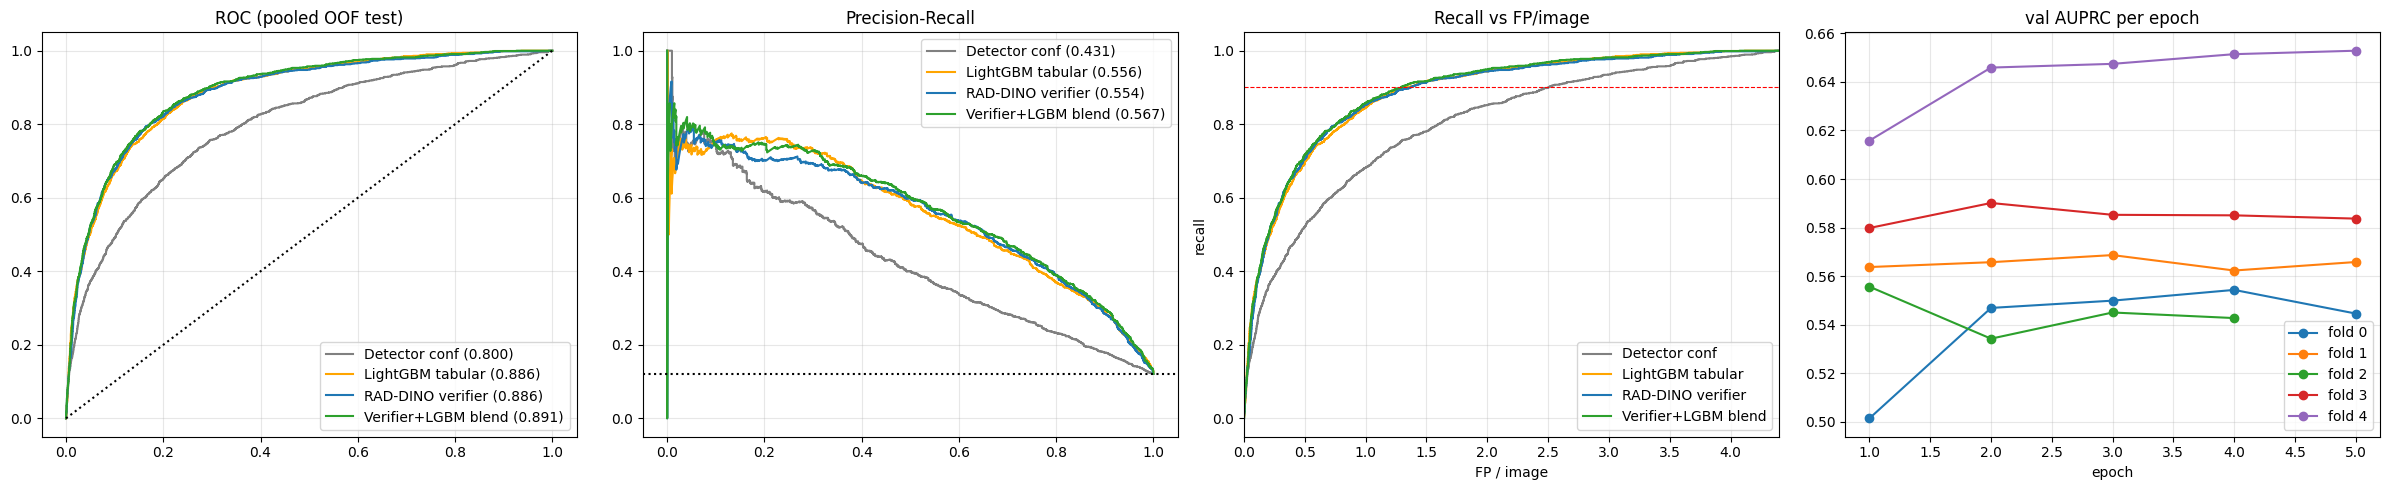

saved -> /kaggle/working/experiments/raddino_cv


In [10]:
fig, ax = plt.subplots(1, 4, figsize=(24, 5)); cols = ["gray", "orange", "tab:blue", "tab:green"]
for (name, (_, s)), c_ in zip(METHODS.items(), cols):
    f_, t_, _ = roc_curve(yt, s); ax[0].plot(f_, t_, color=c_, label=f"{name} ({roc_auc_score(yt, s):.3f})")
    p_, r_, _ = precision_recall_curve(yt, s); ax[1].plot(r_, p_, color=c_, label=f"{name} ({average_precision_score(yt, s):.3f})")
    o = np.argsort(-s); ctp, cfp = np.cumsum(yt[o]), np.cumsum(1 - yt[o]); ax[2].plot(cfp / NPAT, ctp / yt.sum(), color=c_, label=name)   # FROC-style
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_title("ROC (pooled OOF test)"); ax[1].axhline(yt.mean(), color="k", ls=":"); ax[1].set_title("Precision-Recall")
ax[2].axhline(TARGET_RECALL, color="r", ls="--", lw=.8); ax[2].set_xlim(0, base_fp_img); ax[2].set_xlabel("FP / image"); ax[2].set_ylabel("recall"); ax[2].set_title("Recall vs FP/image")
for k in RUN_FOLDS: H = RES[k]["hist"]; ax[3].plot(H[:, 0], H[:, 3], marker="o", label=f"fold {k}")
ax[3].set_title("val AUPRC per epoch"); ax[3].set_xlabel("epoch")
for a_ in ax: a_.grid(alpha=.3); a_.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "cv_results.png"), dpi=200); plt.show()

out = df.iloc[te_i].copy(); out["verifier_score"], out["blend_score"] = vt, METHODS["Verifier+LGBM blend"][1]
out["fold"] = np.concatenate([[k] * len(RES[k]["te"]) for k in RUN_FOLDS])
out.to_csv(os.path.join(OUT_DIR, "oof_test_predictions.csv"), index=False); res.to_csv(os.path.join(OUT_DIR, "pruning_summary.csv"), index=False)
print("saved ->", OUT_DIR)